# FoodWise Assignment 1

Project selection, exploratory data analysis and first NLP experiments

FoodWise helps small soup kitchens and food-service teams find recipes from available ingredients and prioritise ingredients with approaching user-entered use-by dates. The primary SDG link is target 12.3. The first assignment studies ingredient retrieval; it does not establish a measured reduction in food waste.

The bundled corpus is a reproducible sample of real Food.com recipes. Inventory examples and recipe-derived evaluation queries are explicitly simulated. All experiment results below were generated by the code in this notebook.

Run the notebook from the project root or its notebooks folder. Install the packages in requirements.txt first. A pre-executed copy is supplied so figures and results can be inspected immediately.

## 1 Imports and project paths

The code uses pandas and NumPy for analysis, scikit-learn for TF-IDF and latent semantic analysis, and Matplotlib for figures. There is no need to train a large language model for this first experiment.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np

ROOT = Path.cwd()
if not (ROOT / 'data/recipes_sample.jsonl').exists():
    ROOT = ROOT.parent
if not (ROOT / 'data/recipes_sample.jsonl').exists():
    raise FileNotFoundError('Extract the complete project ZIP and run from its root or notebooks folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.foodwise import RecipeRetriever, load_recipes, recovery_benchmark
from src.analysis import eda_figures, benchmark_figure, profile_recipes
OUTPUT = ROOT / 'outputs'
OUTPUT.mkdir(exist_ok=True)
print('Imports completed. Project data and source modules are available.')

Imports completed. Project data and source modules are available.


## 2 Dataset and cleaning decisions

Source: https://www.kaggle.com/datasets/irkaal/foodcom-recipes-and-reviews

The analysis dataset contains exactly 8,000 real recipes sampled reproducibly from the Food.com source. The publisher states CC0 Public Domain. The selected recipes retain 11 fields needed for this assignment, including ingredient names, source quantities, servings, instructions and source nutrition values.

Recipes must have a title, 3-20 distinct normalised ingredients, and a positive known serving count. Duplicate normalised ingredient sets are removed before seed-42 reservoir sampling. No missing serving counts are invented. Source amounts are preserved, but amount-to-ingredient alignment and units are not assumed to be reliable. All EDA and model results below use only these 8,000 records.

USDA FoodData Central is a possible supplementary nutrient source for a later stage. It is not joined to this first experiment: matching ingredient names, quantities, units and portion bases must be validated first.

In [2]:
recipes = load_recipes(ROOT / 'data/recipes_sample.jsonl')
profile = profile_recipes(recipes, sample_seed=42)
(ROOT / 'data/sample_profile.json').write_text(json.dumps(profile, indent=2))
print('Analysis recipes:', f"{profile['rows']:,}")
print('Retained fields:', profile['field_count'])
print('Publication years:', profile['publication_year_min'], 'to', profile['publication_year_max'])
print('Median distinct ingredient count:', profile['ingredient_count']['median'])
quality = pd.DataFrame([
    {'check': key, 'rows': value, 'percent': round(100 * value / profile['rows'], 2)}
    for key, value in profile['quality_flags'].items()
])
print(quality.to_string(index=False))
print()
print('First sample recipes:')
print(pd.DataFrame(recipes)[['recipe_id', 'name', 'category', 'servings']].head().to_string(index=False))

Analysis recipes: 8,000
Retained fields: 11
Publication years: 1999 to 2020
Median distinct ingredient count: 8.0
                              check  rows  percent
quantity_ingredient_length_mismatch  6209    77.61
  quantity_vector_has_missing_entry  2897    36.21
                  servings_above_20   470     5.88

First sample recipes:
recipe_id                                   name        category  servings
       79 Brisket with Sauerkraut and Applesauce       Weeknight       6.0
       92                  Brown Bag Apple Salad         Oranges       4.0
      109    Butterflied Lamb with Garlic Butter      Lamb/Sheep       4.0
      141                   Carrie's Pizza Rolls Low Cholesterol       1.0
      323                        Curried Chicken   Whole Chicken       4.0


## 3 Exploratory data analysis

The plots describe only the 8,000-record analysis sample. The first chart reports quantity/name list mismatches, quantity vectors containing missing entries and recipes whose source serving count exceeds 20. The second chart shows the distribution of the distinct normalised ingredient count. The category plot includes an explicit remainder category.

Interpretation: source quantity problems limit portion-based stock calculations, while ingredient names remain usable for content-based retrieval. High serving values need validation rather than automatic deletion. Because positive known servings were a selection rule, the absence of missing serving values in this sample cannot be generalised to the original source. The predominance of some categories also means this general recipe sample is not representative of soup-kitchen menus.

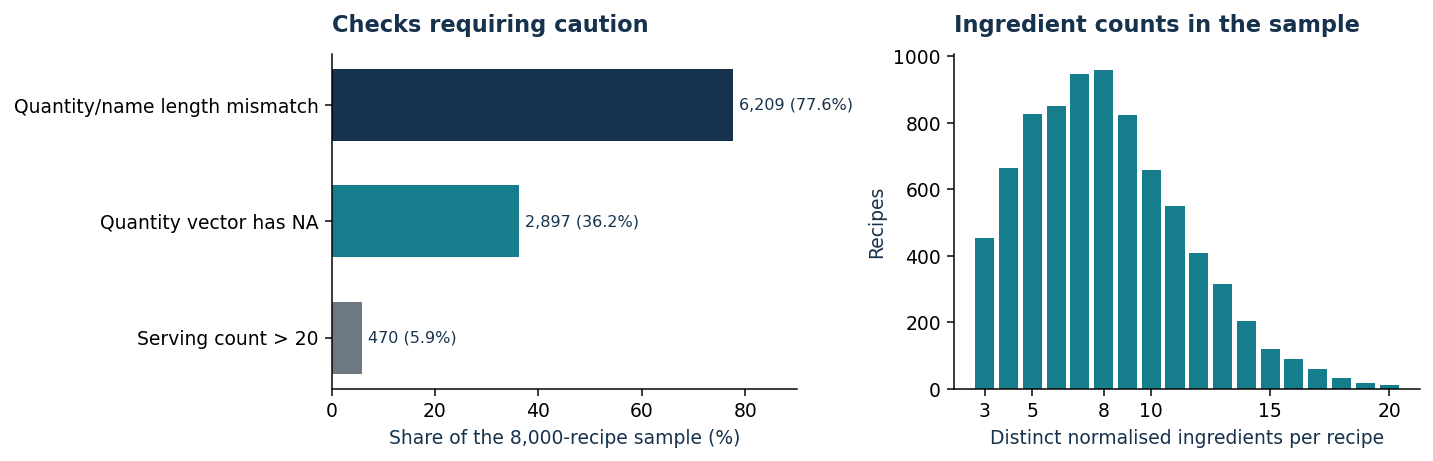

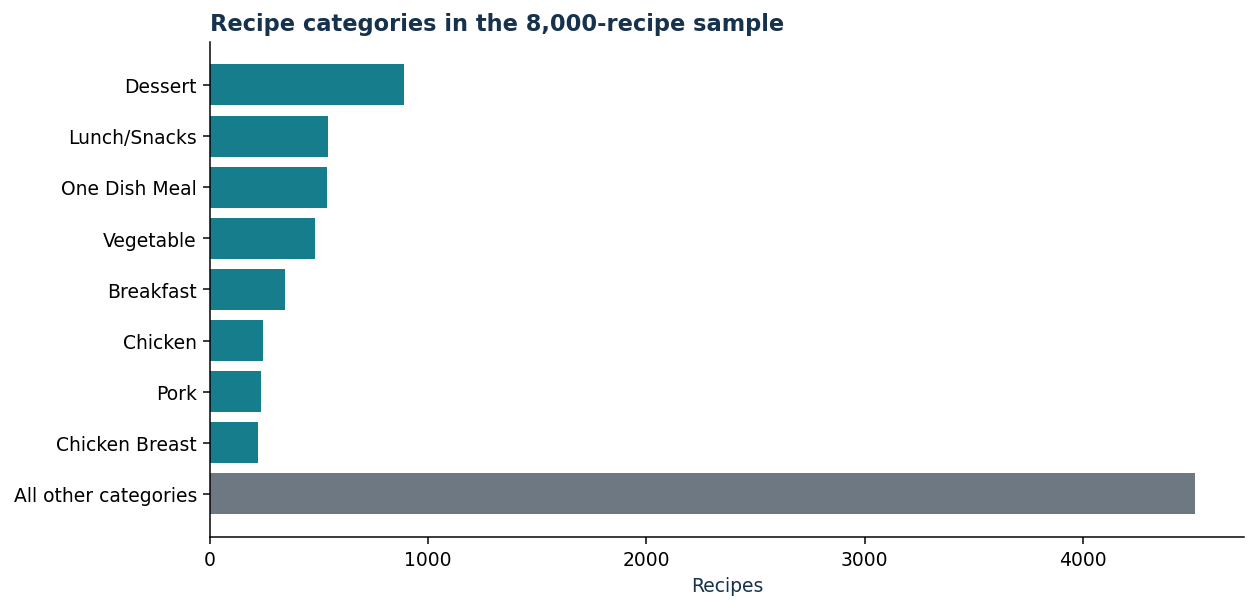

In [3]:
eda_figures(profile, OUTPUT / 'figures')

## 4 First models

Baseline: Jaccard overlap compares the sets of ingredient names.

TF-IDF cosine: the vectoriser learns inverse-document-frequency weights from the recipe corpus. Ingredients that distinguish recipes receive more weight than ingredients found in nearly every recipe. Cosine similarity ranks indexed recipes against a pantry query.

LSA comparison: TruncatedSVD projects the TF-IDF matrix into 64 dimensions. This is a small learned NLP representation for comparing ingredient co-occurrence with direct TF-IDF matching. Model choice is evaluated using the initial benchmark rather than assumed in advance.

Ingredient labels are English and selected from the indexed vocabulary in this pilot. Synonyms and Turkish-to-English matching require separate validation. The expiry-aware score combines 0.60 TF-IDF similarity, 0.30 recipe ingredient coverage and 0.10 coverage of pantry ingredients due within two days. These are initial heuristic weights, not learned or optimised parameters.

In [4]:
engine = RecipeRetriever(recipes).fit_lsa(dimensions=64)
print('TF-IDF matrix:', engine.matrix.shape)
print('LSA dimensions:', engine.latent.shape[1])
print('LSA explained variance share:', round(float(engine.svd.explained_variance_ratio_.sum()), 4))

TF-IDF matrix: (8000, 2874)
LSA dimensions: 64
LSA explained variance share: 0.2823


## 5 Initial model experiment

Protocol: choose 200 recipes with 5-15 ingredients from the indexed corpus using seed 73. Build each query by retaining 60% of its ingredients, with at least 3 and at most 6 retained ingredients. Check whether the source recipe appears in the first 1, 5 or 10 results, and compute mean reciprocal rank.

This is a synthetic source-recipe recovery sanity check. The query recipes are indexed candidates, as in document retrieval; this is not a held-out supervised classification test. Other recipes may be equally suitable. These results do not measure independently judged recommendation quality, actual stock feasibility, nutritional adequacy or food-waste reduction. Future validation will use independently specified pantries and human relevance judgements.

             model  queries  recovery_at_1  recovery_at_5  recovery_at_10  mean_reciprocal_rank
Ingredient overlap      200          0.950           1.00           1.000                0.9742
     TF-IDF cosine      200          0.920           0.99           0.995                0.9536
 LSA 64 dimensions      200          0.455           0.69           0.790                0.5719


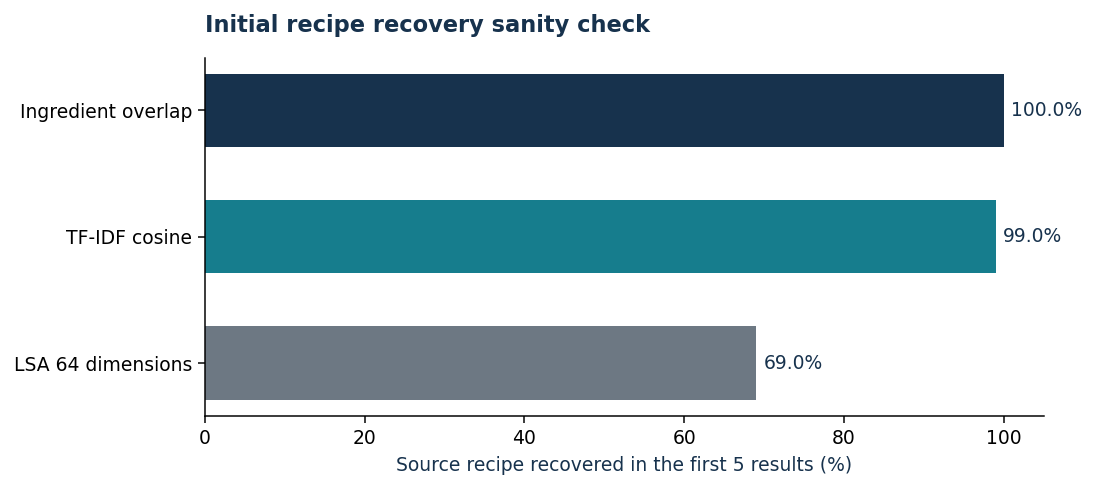

In [5]:
metrics, query_details = recovery_benchmark(engine, n_queries=200, seed=73)
print(metrics.round(4).to_string(index=False))
(OUTPUT / 'initial_metrics.json').write_text(json.dumps(metrics.to_dict(orient='records'), indent=2))
with (OUTPUT / 'recipe_recovery_queries.jsonl').open('w', encoding='utf-8') as f:
    for row in query_details:
        f.write(json.dumps(row, ensure_ascii=False) + chr(10))
benchmark_figure(metrics, OUTPUT / 'figures')

## 6 Illustrative inventory and recommendations

The example inventory below is simulated, with a fixed date so the result is reproducible. Entered dates determine urgency; the application cannot infer food safety from a recipe or date alone. Items entered as unusable or past the entered date are removed from available stock.

Ingredient coverage is a count of distinct ingredient types, not a mass or portion-feasibility measure. Recipes whose ingredient types are all available are placed first; the weighted score orders recipes within that group. Missing ingredients are shown rather than silently treated as available. Quantities are retained in the example input for future work but are not used to claim that enough grams or litres exist.

In [6]:
inventory_example = json.loads((ROOT / 'data/example_inventory.json').read_text())
print('Illustrative scenario date:', inventory_example['as_of'])
print(pd.DataFrame(inventory_example['items']).to_string(index=False))
recommendations = engine.recommend(inventory_example['items'], inventory_example['as_of'], top_k=5)
print()
print('Top recommendations:')
print(recommendations[['name', 'score', 'ingredient_coverage', 'urgent_coverage', 'missing_ingredients']].round(3).to_string(index=False, max_colwidth=70))
(OUTPUT / 'demo_recommendations.json').write_text(recommendations.to_json(orient='records', indent=2))

Illustrative scenario date: 2026-10-17
    ingredient  quantity  unit     use_by  usable
chicken pieces         2    kg 2026-10-18    True
      tomatoes         2    kg 2026-10-18    True
         onion         1    kg 2026-10-19    True
        garlic       100     g 2026-10-24    True
     olive oil         1 litre 2026-11-17    True
          salt       500     g 2026-12-17    True
  black pepper       100     g 2026-12-17    True
          rice         2    kg 2026-11-17    True
         water         5 litre 2026-10-24    True

Top recommendations:
                                                            name  score  ingredient_coverage  urgent_coverage                                       missing_ingredients
                             Simple Crock Pot Chicken Cacciatore  0.879                1.000            1.000                                                        []
Chef Flower's Turkish Cypriot Taro Casserole - Kibrisli  Kolokas  0.534                0.556           

## 7 Basic functional checks

These checks cover distinct source identities, retained serving information, unknown pantry items and exclusion of unavailable stock. They supplement the retrieval experiment and do not replace future user testing.

In [7]:
assert len(recipes) == profile['rows'] == 8000
assert len({r['recipe_id'] for r in recipes}) == len(recipes)
assert all(r['servings'] > 0 for r in recipes)
assert engine.recommend([{'ingredient': 'unseen_example_ingredient_987', 'use_by': '2026-10-20'}], '2026-10-17').empty
assert engine.recommend([{'ingredient': term, 'use_by': '2026-10-16'} for term in recipes[0]['ingredients']], '2026-10-17').empty
print('Functional checks passed: source IDs, positive servings, unknown inputs and date exclusion.')

Functional checks passed: source IDs, positive servings, unknown inputs and date exclusion.


## 8 Scope and next work

Assignment 1 delivers project selection, source justification, EDA and first NLP experiments. It does not claim a deployed application or measured food-waste savings.

Next stages: validate synonyms or multilingual embeddings, create independently specified evaluation pantries, review date handling and ingredient restrictions with users, curate reliable amount/unit mappings, and build a small interface. A real pilot would need stock and waste measurements before and after use to assess SDG impact.

References

- UN SDG 12 and target 12.3: https://sdgs.un.org/goals/goal12
- Food.com source: https://www.kaggle.com/datasets/irkaal/foodcom-recipes-and-reviews
- TF-IDF documentation: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- TruncatedSVD documentation: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html
- USDA supplementary source: https://fdc.nal.usda.gov/download-datasets/

The classmate's water-potability notebook was reviewed for the high-level EDA organisation. FoodWise code and evaluation address ingredient-based recipe retrieval.